<a href="https://colab.research.google.com/github/costpetrides/Box_Model/blob/main/Box_Model_Group1_Excel_ONLY_with_PPT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Box Model — Ομάδα 1 | Αποκλειστικά από Excel

Αυτό το notebook χρησιμοποιεί **αποκλειστικά** το αρχείο `Apotelesmata_ody(2).xlsx` και αναπαράγει τα διαγράμματα του [πρωτότυπου notebook](https://github.com/costpetrides/Box_Model/blob/main/Box_Model_Group1_ALL_POINTS.ipynb).

**Μοναδική πηγή δεδομένων:** `EXCEL_PATH`. Διαβάζει τις απαιτούμενες στήλες από τα 12 φύλλα του Excel. Αν το αρχείο απουσιάζει ή λείπουν απαιτούμενα δεδομένα, το notebook **σταματά με σφάλμα**. Δεν υπάρχουν ενσωματωμένα δεδομένα, άλλες εκδόσεις του Excel, CSV ή λήψη από GitHub.

Για το **Google Colab**, ανεβάστε πρώτα το `Apotelesmata_ody(2).xlsx` στο **Files** → **Upload**. Έπειτα εκτελέστε **Runtime → Run all**. Σε τοπικό Jupyter, αποθηκεύστε το Excel στον ίδιο φάκελο με το notebook (ή αλλάξτε ρητά το `EXCEL_PATH`).

| Σχήμα | Χημικά είδη | Άξονες |
|---|---|---|
| 1 | O₃, NO, NO₂ | O₃ αριστερά · NO/NO₂ δεξιά |
| 2 | O₃, OH | O₃ αριστερά · OH δεξιά |
| 3 | ALK4, CO | ALK4 αριστερά · CO δεξιά |
| 4 | HNO₃ | HNO₃ αριστερά |

Παράγονται 18 κύρια σχήματα, 16 επιπλέον σχήματα, πάνελ 16:9, συγκριτικό O₃, PowerPoint και ZIP. Οι κλίμακες είναι κοινές μεταξύ συγκρίσιμων διαγραμμάτων.

**Μονάδες:** Το Excel δεν αναγράφει ρητά μονάδες συγκέντρωσης. Η επιλογή `ppb` αποτελεί εκτίμηση από τις τάξεις μεγέθους, όχι επιβεβαιωμένη μονάδα του μοντέλου.


## 1. Βιβλιοθήκες και ρυθμίσεις

In [1]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from hashlib import sha256
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, ScalarFormatter
from IPython.display import display, Image

# ONLY data source. No CSVs, embedded tables, or automatic filename matching.
EXCEL_PATH = Path('Apotelesmata_ody.xlsx')
OUTPUT_DIR = Path('Box_Model_Ody_Excel_Only_Output')
SAVE_PDF = True
MAKE_SLIDE_PANELS = True
MAKE_O3_COMPARISON = True
MAKE_SUPPLEMENTARY = True
UNIT = 'ppb'  # Estimated from magnitudes; confirm using original model.

FIGURE_DPI = 300
SLIDE_DPI = 180

plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 10,
    'axes.titlesize': 12, 'axes.labelsize': 10,
    'axes.spines.top': False, 'figure.facecolor': 'white',
    'savefig.facecolor': 'white', 'pdf.fonttype': 42,
})


## 2. Αντιστοίχιση των 12 φύλλων Excel στα σενάρια

In [2]:
SCENARIOS = {
    'baseline': {"label": 'Βασικό σενάριο', "sheet": '1o output', "figures": [1, 2, 3, 4], "required": True},
    'hv0': {"label": 'HV = 0', "sheet": 'HV=0.000', "figures": [1, 2], "required": True},
    'lat57': {"label": 'LAT = 57°', "sheet": 'Lat=57', "figures": [1, 2], "required": True},
    'mix400': {"label": 'Mixing height = 400 m', "sheet": 'MH=400', "figures": [1, 3], "required": True},
    'nox_half': {"label": 'NOx / 2', "sheet": 'TOTNOX dia2', "figures": [1, 4], "required": True},
    'voc_half': {"label": 'VOC / 2', "sheet": 'TOTVOX dia2', "figures": [1, 4], "required": True},
    'nox_x2': {"label": 'NOx × 2', "sheet": 'TOTNOX X2', "figures": [1, 4], "required": True},
    'voc_x2': {"label": 'VOC × 2', "sheet": 'TOTVOX X2', "figures": [1, 4], "required": True},
    'alo012': {"label": 'ALO = 0.12', "sheet": 'ALO 0.12', "figures": [1, 2, 3, 4], "required": False},
    'propane': {"label": 'Propane = 0.219', "sheet": 'LUMP MONO PROPANE 0.219', "figures": [1, 2, 3, 4], "required": False},
    'propene': {"label": 'Propene = 0.219', "sheet": 'LUMP MONO PROPENE 0.219', "figures": [1, 2, 3, 4], "required": False},
    'h2o': {"label": 'Water vapour = 2.059 × 10⁴ (constant)', "sheet": 'WATER VAPOR 2.059E+04=const', "figures": [1, 2, 3, 4], "required": False},
}

FIGURES = {
    1: {'title':'O₃, NO, NO₂', 'left':['O3'], 'right':['NO','NO2']},
    2: {'title':'O₃, OH', 'left':['O3'], 'right':['OH']},
    3: {'title':'ALK4, CO', 'left':['ALK4'], 'right':['CO']},
    4: {'title':'HNO₃', 'left':['HNO3'], 'right':[]},
}
COLORS = {
    'O3':'#D24B42', 'NO':'#2867AA', 'NO2':'#8053A5',
    'OH':'#C18D11', 'ALK4':'#278371', 'CO':'#DA8425',
    'HNO3':'#515D6B',
}
CHEM_LABELS = {
    'O3':r'$O_3$', 'NO':r'$NO$', 'NO2':r'$NO_2$',
    'OH':r'$OH$', 'ALK4':'ALK4', 'CO':'CO', 'HNO3':r'$HNO_3$',
}
REQUIRED_COLUMNS = ['Time','O3','NO','NO2','OH','ALK4','CO','HNO3']
assert sum(len(s['figures']) for s in SCENARIOS.values() if s['required']) == 18
print('8 κύρια σενάρια / 18 βασικά σχήματα')
print('4 πρόσθετα σενάρια / 16 συμπληρωματικά σχήματα (αν ενεργοποιηθούν)')

8 κύρια σενάρια / 18 βασικά σχήματα
4 πρόσθετα σενάρια / 16 συμπληρωματικά σχήματα (αν ενεργοποιηθούν)


## 3. Ανάγνωση, αριθμητική μετατροπή και έλεγχος του Excel

In [3]:
def load_excel_scenario(workbook, sheet):
    """Read a named sheet from the ONE explicitly selected Excel workbook."""
    # Headers are in Excel row 6; rows 1-5 are metadata.
    frame = pd.read_excel(workbook, sheet_name=sheet, header=5, engine='openpyxl')
    frame.columns = [str(c).strip() for c in frame.columns]
    missing = sorted(set(REQUIRED_COLUMNS) - set(frame.columns))
    if missing:
        raise ValueError(f'Excel sheet {sheet!r}: missing required columns {missing}')
    if frame.columns.duplicated().any():
        raise ValueError(f'Excel sheet {sheet!r}: duplicated column headers')
    return frame[REQUIRED_COLUMNS].dropna(how='all').copy()


def validate_scenario(frame, label):
    df = frame.copy()
    if len(df) != 19:
        raise ValueError(f'{label}: expected 19 hourly records, got {len(df)}')
    for key in REQUIRED_COLUMNS:
        df[key] = pd.to_numeric(df[key], errors='raise')
        if not np.isfinite(df[key].to_numpy(dtype=float)).all():
            raise ValueError(f'{label}: nonfinite value in {key}')
    times = df['Time'].to_numpy(dtype=float)
    if not np.allclose(times, np.arange(360,1441,60), rtol=0, atol=1e-9):
        raise ValueError(f'{label}: unexpected hourly timestamps')
    for key in REQUIRED_COLUMNS[1:]:
        if (df[key] < -1e-12).any():
            raise ValueError(f'{label}: negative concentration in {key}')
    df['Hour'] = times / 60.0
    return df.reset_index(drop=True)

# A missing workbook is an error, NEVER a reason to load other data.
workbook_path = EXCEL_PATH.expanduser().resolve(strict=False)
if not workbook_path.is_file():
    raise FileNotFoundError(
        f'Excel file not found: {workbook_path}\n'
        'Upload Apotelesmata_ody(2).xlsx to this notebook folder '
        'or explicitly change EXCEL_PATH. No fallback is permitted.'
    )

workbook_sha256 = sha256(workbook_path.read_bytes()).hexdigest()
source = str(workbook_path)
print(f'ONLY INPUT FILE: {source}')
print(f'Excel SHA-256: {workbook_sha256}')

# Verify all required named sheets exist in that workbook.
with pd.ExcelFile(workbook_path, engine='openpyxl') as workbook:
    expected_sheets = [s['sheet'] for s in SCENARIOS.values()]
    missing_sheets = sorted(set(expected_sheets) - set(workbook.sheet_names))
    if missing_sheets:
        raise ValueError(f'Missing sheets in {workbook_path.name}: {missing_sheets}')

    data = {}
    for sid, spec in SCENARIOS.items():
        raw = load_excel_scenario(workbook, spec['sheet'])
        data[sid] = validate_scenario(raw, spec['sheet'])

base_times = data['baseline']['Time'].to_numpy()
for sid, df in data.items():
    if not np.array_equal(df['Time'].to_numpy(), base_times):
        raise ValueError(f'{sid}: time grid differs from the baseline')

summary = pd.DataFrame([{
    'scenario': spec['label'], 'Excel sheet': spec['sheet'],
    'data points': len(data[sid]), 'hour first': data[sid]['Hour'].iat[0],
    'hour last': data[sid]['Hour'].iat[-1], 'primary': spec['required'],
    'Excel SHA-256': workbook_sha256,
} for sid, spec in SCENARIOS.items()])
display(summary)
print('Verified: all 12 scenarios were read from the one Excel file.')


ONLY INPUT FILE: /content/Apotelesmata_ody.xlsx
Excel SHA-256: c1f13d4819e31d0b383761ee1d9c9c66a1a7c650b3dc04ab58f307a830bb62b2


,scenario,Excel sheet,data points,hour first,hour last,primary,Excel SHA-256
0,Βασικό σενάριο,1o output,19,6.0,24.0,True,c1f13d4819e31d0b383761ee1d9c9c66a1a7c650b3dc04...
1,HV = 0,HV=0.000,19,6.0,24.0,True,c1f13d4819e31d0b383761ee1d9c9c66a1a7c650b3dc04...
2,LAT = 57°,Lat=57,19,6.0,24.0,True,c1f13d4819e31d0b383761ee1d9c9c66a1a7c650b3dc04...
3,Mixing height = 400 m,MH=400,19,6.0,24.0,True,c1f13d4819e31d0b383761ee1d9c9c66a1a7c650b3dc04...
4,NOx / 2,TOTNOX dia2,19,6.0,24.0,True,c1f13d4819e31d0b383761ee1d9c9c66a1a7c650b3dc04...
5,VOC / 2,TOTVOX dia2,19,6.0,24.0,True,c1f13d4819e31d0b383761ee1d9c9c66a1a7c650b3dc04...
6,NOx × 2,TOTNOX X2,19,6.0,24.0,True,c1f13d4819e31d0b383761ee1d9c9c66a1a7c650b3dc04...
7,VOC × 2,TOTVOX X2,19,6.0,24.0,True,c1f13d4819e31d0b383761ee1d9c9c66a1a7c650b3dc04...
8,ALO = 0.12,ALO 0.12,19,6.0,24.0,False,c1f13d4819e31d0b383761ee1d9c9c66a1a7c650b3dc04...
9,Propane = 0.219,LUMP MONO PROPANE 0.219,19,6.0,24.0,False,c1f13d4819e31d0b383761ee1d9c9c66a1a7c650b3dc04...


Verified: all 12 scenarios were read from the one Excel file.


## 4. Κοινές κλίμακες για συγκρίσιμες συγκεντρώσεις

In [4]:
def rounded_upper(maximum):
    if not np.isfinite(maximum) or maximum <= 0:
        return 1.0
    v = maximum * 1.08
    p = 10.0 ** np.floor(np.log10(v))
    ticks = np.array([1, 1.2, 1.25, 1.5, 2, 2.5, 3, 3.5, 4, 5, 6, 7, 8, 10])
    idx = min(int(np.searchsorted(ticks, v/p, side='left')), len(ticks)-1)
    return float(ticks[idx]*p)

# O3 appears in both Figs 1 and 2; use the SAME limit in both.
active_ids = [sid for sid,s in SCENARIOS.items() if s['required'] or MAKE_SUPPLEMENTARY]
all_max = {k: max(float(data[sid][k].max()) for sid in active_ids)
           for k in REQUIRED_COLUMNS[1:]}
species_scales = {k: (0, rounded_upper(v)) for k,v in all_max.items()}

# NO & NO2 share the right axis in Figure 1.
SCALES = {
    1: {'left':species_scales['O3'],
        'right':(0, rounded_upper(max(all_max['NO'],all_max['NO2'])))},
    2: {'left':species_scales['O3'], 'right':species_scales['OH']},
    3: {'left':species_scales['ALK4'], 'right':species_scales['CO']},
    4: {'left':species_scales['HNO3']},
}
assert SCALES[1]['left'] == SCALES[2]['left']
for no, axes in SCALES.items():
    print(f'Σχ. {no}: {axes}')

Σχ. 1: {'left': (0, 400.0), 'right': (0, 120.0)}
Σχ. 2: {'left': (0, 400.0), 'right': (0, 0.0012)}
Σχ. 3: {'left': (0, 40.0), 'right': (0, 350.0)}
Σχ. 4: {'left': (0, 100.0)}


## 5. Συνάρτηση σχεδίασης των τεσσάρων σχημάτων

In [5]:
def draw_on_axis(ax, df, figure_no, compact=False):
    spec = FIGURES[figure_no]
    scales = SCALES[figure_no]
    x = df['Hour'].to_numpy()
    handles = []
    plot_kw = dict(linewidth=1.8 if compact else 2.2,
                   marker='o', markersize=2.7 if compact else 3.5,
                   markevery=1, zorder=3)
    for chemical in spec['left']:
        (line,) = ax.plot(x, df[chemical].to_numpy(),
                          color=COLORS[chemical], label=CHEM_LABELS[chemical],
                          **plot_kw)
        handles.append(line)
    ax.set(xlim=(6,24), ylim=scales['left'], xlabel='Ώρα ημέρας [h]')
    ax.set_ylabel(', '.join(spec['left']) + f' [{UNIT}]')
    ax.xaxis.set_major_locator(MultipleLocator(3))
    ax.grid(True, color='#B9C0C8', alpha=.4, linewidth=.7)
    ax.set_axisbelow(True)
    ax.spines['right'].set_visible(False)

    if spec['right']:
        ax2 = ax.twinx()
        for chemical in spec['right']:
            (line,) = ax2.plot(x, df[chemical].to_numpy(),
                               color=COLORS[chemical], label=CHEM_LABELS[chemical],
                               **plot_kw)
            handles.append(line)
        ax2.set_ylim(scales['right'])
        ax2.set_ylabel(', '.join(spec['right']) + f' [{UNIT}]')
        ax2.spines['top'].set_visible(False)
        ax2.grid(False)
        if 'OH' in spec['right']:
            form = ScalarFormatter(useMathText=True)
            form.set_powerlimits((0,0))
            ax2.yaxis.set_major_formatter(form)
    return handles


def make_figure(sid, number):
    fig, ax = plt.subplots(figsize=(9,4.9))
    hs = draw_on_axis(ax, data[sid], number)
    fig.suptitle(f'{SCENARIOS[sid]["label"]}  |  Σχ. {number}: {FIGURES[number]["title"]}',
                 y=.975, fontsize=13)
    fig.legend(handles=hs, loc='upper center', bbox_to_anchor=(.5,.91),
               ncol=len(hs), fontsize=11, frameon=False)
    fig.subplots_adjust(left=.11, right=.87, bottom=.15, top=.77)
    return fig

## 6. Εξαγωγή των 18 απαιτούμενων σχημάτων από το Excel

In [6]:
FIGURES_DIR = OUTPUT_DIR / '01_required_figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
manifest = []

def save_figure(sid, fig_no, folder, category):
    fig = make_figure(sid, fig_no)
    basename = f'{sid}_Fig{fig_no}'
    png = folder / f'{basename}.png'
    fig.savefig(png, dpi=FIGURE_DPI, bbox_inches='tight')
    if SAVE_PDF:
        fig.savefig(folder / f'{basename}.pdf', bbox_inches='tight')
    plt.close(fig)
    manifest.append(dict(scenario=sid, label=SCENARIOS[sid]['label'],
                         source_excel_sheet=SCENARIOS[sid]['sheet'],
                         figure=fig_no, category=category,
                         chemical_species=', '.join(FIGURES[fig_no]['left'] + FIGURES[fig_no]['right']),
                         png=str(png)))

for sid, spec in SCENARIOS.items():
    if spec['required']:
        for fig_no in spec['figures']:
            save_figure(sid, fig_no, FIGURES_DIR, 'required')
assert sum(x['category']=='required' for x in manifest) == 18
print('Ολοκληρώθηκαν 18 βασικά σχήματα από 8 σενάρια.')

Ολοκληρώθηκαν 18 βασικά σχήματα από 8 σενάρια.


## 7. Συμπληρωματικά σχήματα των τεσσάρων επιπλέον φύλλων Excel

In [7]:
EXTRAS_DIR = OUTPUT_DIR / '04_supplementary_figures'
if MAKE_SUPPLEMENTARY:
    EXTRAS_DIR.mkdir(parents=True, exist_ok=True)
    for sid, spec in SCENARIOS.items():
        if not spec['required']:
            for fig_no in spec['figures']:
                save_figure(sid, fig_no, EXTRAS_DIR, 'supplementary')
    assert sum(x['category']=='supplementary' for x in manifest) == 16
    print('Ολοκληρώθηκαν 16 συμπληρωματικά σχήματα από 4 επιπλέον σενάρια.')
manifest_df = pd.DataFrame(manifest)
manifest_df.to_csv(OUTPUT_DIR / 'figure_manifest.csv', index=False, encoding='utf-8-sig')
display(manifest_df[['label','figure','chemical_species','category']])

Ολοκληρώθηκαν 16 συμπληρωματικά σχήματα από 4 επιπλέον σενάρια.


,label,figure,chemical_species,category
0,Βασικό σενάριο,1,"O3, NO, NO2",required
1,Βασικό σενάριο,2,"O3, OH",required
2,Βασικό σενάριο,3,"ALK4, CO",required
3,Βασικό σενάριο,4,HNO3,required
4,HV = 0,1,"O3, NO, NO2",required
5,HV = 0,2,"O3, OH",required
6,LAT = 57°,1,"O3, NO, NO2",required
7,LAT = 57°,2,"O3, OH",required
8,Mixing height = 400 m,1,"O3, NO, NO2",required
9,Mixing height = 400 m,3,"ALK4, CO",required


## 8. Πάνελ 16:9 έτοιμα για τοποθέτηση σε διαφάνειες

In [8]:
SLIDES_DIR = OUTPUT_DIR / '02_slide_panels'
if MAKE_SLIDE_PANELS:
    SLIDES_DIR.mkdir(parents=True, exist_ok=True)
    for sid, spec in SCENARIOS.items():
        if not (spec['required'] or MAKE_SUPPLEMENTARY):
            continue
        fig_nos = spec['figures']
        nrows, ncols = (2,2) if len(fig_nos)==4 else (1,2)
        fig, axes = plt.subplots(nrows, ncols, figsize=(16,9))
        axes = np.atleast_1d(axes).ravel()
        for ax, no in zip(axes, fig_nos):
            hs = draw_on_axis(ax, data[sid], no, compact=True)
            ax.set_title(f'Σχ. {no} — {FIGURES[no]["title"]}', pad=13)
            ax.legend(handles=hs, loc='upper left', frameon=True,
                      facecolor='white', edgecolor='#E1E4E8',
                      fontsize=9, ncol=1 if len(hs)==1 else len(hs))
        fig.suptitle(spec['label'], fontsize=19, y=.974)
        if nrows==2:
            fig.subplots_adjust(left=.075, right=.925, top=.88,
                                bottom=.095, wspace=.34, hspace=.45)
        else:
            fig.subplots_adjust(left=.075, right=.925, top=.84,
                                bottom=.19, wspace=.34)
        fig.savefig(SLIDES_DIR / f'slide_{sid}.png', dpi=SLIDE_DPI)
        plt.close(fig)
    print(f'Ολοκληρώθηκαν {len(list(SLIDES_DIR.glob("*.png")))} πάνελ 16:9.')

Ολοκληρώθηκαν 12 πάνελ 16:9.


## 9. Συγκριτικό O₃ σε κοινή κλίμακα για όλα τα σενάρια

In [9]:
COMPARE_DIR = OUTPUT_DIR / '03_optional_comparison'
if MAKE_O3_COMPARISON:
    COMPARE_DIR.mkdir(parents=True, exist_ok=True)
    fig, ax = plt.subplots(figsize=(11.5, 6))
    palette = list(plt.get_cmap('tab20').colors)
    for i,sid in enumerate(active_ids):
        df = data[sid]
        ax.plot(df['Hour'], df['O3'], label=SCENARIOS[sid]['label'],
                color='#202833' if sid=='baseline' else palette[(2*i)%len(palette)],
                linewidth=2.8 if sid=='baseline' else 1.7,
                linestyle='--' if sid=='baseline' else '-',
                marker='o', markevery=1, markersize=2.5)
    ax.set(xlim=(6,24), ylim=SCALES[1]['left'],
           xlabel='Ώρα ημέρας [h]', ylabel=f'O₃ [{UNIT}]',
           title='Σύγκριση O₃ — δεδομένα Οδυσσέα')
    ax.xaxis.set_major_locator(MultipleLocator(3))
    ax.grid(True, color='#B9C0C8', alpha=.4, linewidth=.7)
    ax.legend(loc='upper left', bbox_to_anchor=(1.01,1), frameon=False, fontsize=8.5)
    fig.subplots_adjust(left=.10, right=.68, bottom=.13, top=.89)
    fig.savefig(COMPARE_DIR / 'O3_all_scenarios.png', dpi=FIGURE_DPI, bbox_inches='tight')
    if SAVE_PDF:
        fig.savefig(COMPARE_DIR / 'O3_all_scenarios.pdf', bbox_inches='tight')
    plt.close(fig)
    print(f'Συγκριτικό O₃: {len(active_ids)} σενάρια.')

Συγκριτικό O₃: 12 σενάρια.


In [10]:
# =========================================================
# Optional comparison plots for multiple species
# O3, NO, NO2, CO, OH across all scenarios
# =========================================================

COMPARE_DIR = OUTPUT_DIR / "03_species_comparisons"
COMPARE_DIR.mkdir(parents=True, exist_ok=True)

MAKE_MULTI_SPECIES_COMPARISON = True

COMPARE_SPECIES = ["O3", "NO", "NO2", "CO", "OH"]

# labels for titles / axes
COMPARE_LABELS = {
    "O3": r"$O_3$",
    "NO": r"$NO$",
    "NO2": r"$NO_2$",
    "CO": "CO",
    "OH": "OH",
}

# use the same scale logic as the rest of the notebook
def species_ylim(species):
    vals = []
    for scenario_id in SCENARIOS:
        vals.extend(data[scenario_id][species].to_numpy())
    return (0.0, rounded_upper(np.max(vals)))

# line colors per scenario
scenario_colors = [
    "#202833", "#6D7380", "#2867AA", "#278371",
    "#D24B42", "#C18D11", "#8053A5", "#DA8425",
    "#B5B51E", "#18A7C9", "#1F77B4", "#FF7F0E"
]

def make_species_comparison_plot(species):
    fig, ax = plt.subplots(figsize=(10.6, 5.4))

    for (scenario_id, scenario), color in zip(SCENARIOS.items(), scenario_colors):
        df = data[scenario_id]

        ax.plot(
            df["Hour"],
            df[species],
            label=scenario["label"],
            color=color,
            linewidth=2.6 if scenario_id == "baseline" else 1.7,
            linestyle="--" if scenario_id == "baseline" else "-",
            marker="o",
            markevery=1,
            markersize=2.6
        )

    ax.set_xlim(6, 24)
    ax.set_ylim(*species_ylim(species))
    ax.set_xlabel("Ώρα ημέρας [h]")
    ax.set_ylabel(f"{COMPARE_LABELS[species]} [ppb]")
    ax.set_title(f"Σύγκριση {COMPARE_LABELS[species]}")

    ax.xaxis.set_major_locator(MultipleLocator(3))
    ax.grid(True, color="#B9C0C8", alpha=0.40, linewidth=0.7)

    # OH often needs scientific notation
    if species == "OH":
        formatter = ScalarFormatter(useMathText=True)
        formatter.set_powerlimits((0, 0))
        ax.yaxis.set_major_formatter(formatter)

    ax.legend(
        loc="upper left",
        bbox_to_anchor=(1.01, 1),
        frameon=False,
        fontsize=9
    )

    fig.subplots_adjust(left=0.10, right=0.70, bottom=0.13, top=0.89)

    png_path = COMPARE_DIR / f"{species}_all_scenarios.png"
    pdf_path = COMPARE_DIR / f"{species}_all_scenarios.pdf"

    fig.savefig(png_path, dpi=300, bbox_inches="tight")
    fig.savefig(pdf_path, bbox_inches="tight")
    plt.close(fig)

    return png_path

comparison_files = {}

if MAKE_MULTI_SPECIES_COMPARISON:
    for sp in COMPARE_SPECIES:
        comparison_files[sp] = make_species_comparison_plot(sp)

    print("Created comparison plots for:", ", ".join(COMPARE_SPECIES))

Created comparison plots for: O3, NO, NO2, CO, OH


## 10. Δημιουργία PowerPoint (.pptx) από τα έτοιμα διαγράμματα

Δημιουργείται 16:9 παρουσίαση: εξώφυλλο, 8 κύρια σενάρια, 4 συμπληρωματικά σενάρια (εφόσον είναι ενεργά) και προαιρετικά σύγκριση O₃. Οι τίτλοι εξωφύλλου είναι επεξεργάσιμοι· τα διαγράμματα ενσωματώνονται ως υψηλής ποιότητας εικόνες.

In [11]:

# ============================================================
# PowerPoint Export — Box Model (Odysseas Excel Data)
# 12 Scenario Slides + 5 Species Comparison Slides
# ============================================================

try:
    from pptx import Presentation
    from pptx.util import Inches, Pt
    from pptx.dml.color import RGBColor
    from pptx.enum.shapes import MSO_SHAPE
except ImportError:
    import subprocess, sys
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "python-pptx"
    ])
    from pptx import Presentation
    from pptx.util import Inches, Pt
    from pptx.dml.color import RGBColor
    from pptx.enum.shapes import MSO_SHAPE

from PIL import Image as PILImage

# ------------------------------------------------------------
# Settings
# ------------------------------------------------------------

MAKE_PPT = True
INCLUDE_EXTRA_PPT_SCENARIOS = MAKE_SUPPLEMENTARY
INCLUDE_COMPARISON_SLIDES = True

COMPARE_SPECIES = ["O3", "NO", "NO2", "CO", "OH"]

PPT_LABELS = {
    "O3": "O₃",
    "NO": "NO",
    "NO2": "NO₂",
    "CO": "CO",
    "OH": "OH",
}

# ------------------------------------------------------------
# Create PowerPoint
# ------------------------------------------------------------

if MAKE_PPT:

    if not MAKE_SLIDE_PANELS:
        raise RuntimeError(
            "Set MAKE_SLIDE_PANELS = True and rerun the notebook."
        )

    prs = Presentation()
    prs.slide_width = Inches(13.333333)
    prs.slide_height = Inches(7.5)

    blank = prs.slide_layouts[6]

    # --------------------------------------------------------
    # Helper: Add text
    # --------------------------------------------------------

    def add_text(slide, text, x, y, width, height,
                 size, color, bold=False):

        shape = slide.shapes.add_textbox(
            Inches(x), Inches(y),
            Inches(width), Inches(height)
        )

        tf = shape.text_frame
        tf.word_wrap = True

        p = tf.paragraphs[0]
        p.text = text
        p.font.size = Pt(size)
        p.font.bold = bold
        p.font.name = "Aptos"
        p.font.color.rgb = RGBColor(*color)

        return shape

    # --------------------------------------------------------
    # Helper: Add image without distortion
    # --------------------------------------------------------

    def add_fitted_image(slide, image_path,
                         x=0.65, y=1.0,
                         max_width=12.0, max_height=6.0):

        with PILImage.open(image_path) as img:
            pw, ph = img.size

        available_w = Inches(max_width)
        available_h = Inches(max_height)

        scale = min(
            available_w / pw,
            available_h / ph
        )

        w = int(pw * scale)
        h = int(ph * scale)

        left = Inches(x) + (available_w - w) // 2
        top = Inches(y) + (available_h - h) // 2

        slide.shapes.add_picture(
            str(image_path),
            left, top,
            width=w,
            height=h
        )

    # ========================================================
    # 1. Cover Slide
    # ========================================================

    slide = prs.slides.add_slide(blank)

    bg = slide.shapes.add_shape(
        MSO_SHAPE.RECTANGLE,
        0, 0,
        prs.slide_width,
        prs.slide_height
    )

    bg.fill.solid()
    bg.fill.fore_color.rgb = RGBColor(29, 37, 45)
    bg.line.fill.background()

    add_text(
        slide, "BOX MODEL",
        0.9, 2.0, 11.5, 0.8,
        37, (246, 247, 249), True
    )

    add_text(
        slide, "Ομάδα 1 | Αποτελέσματα προσομοιώσεων",
        0.9, 3.05, 11.5, 0.6,
        22, (215, 220, 226)
    )

    add_text(
        slide, f"Δεδομένα: {workbook_path.name}",
        0.9, 5.55, 11.5, 0.4,
        13, (183, 192, 201)
    )

    add_text(
        slide, f"Συγκεντρώσεις: {UNIT} (μονάδα υπό επιβεβαίωση)",
        0.9, 6.12, 11.5, 0.35,
        11, (183, 192, 201)
    )

    # ========================================================
    # 2. Scenario Slides
    # ========================================================

    ordered_ids = [
        sid for sid, s in SCENARIOS.items()
        if s["required"]
    ]

    if INCLUDE_EXTRA_PPT_SCENARIOS:
        ordered_ids += [
            sid for sid, s in SCENARIOS.items()
            if not s["required"]
        ]

    for sid in ordered_ids:

        panel = SLIDES_DIR / f"slide_{sid}.png"

        if not panel.is_file():
            raise FileNotFoundError(
                f"Missing slide panel: {panel}"
            )

        slide = prs.slides.add_slide(blank)

        slide.shapes.add_picture(
            str(panel),
            0, 0,
            width=prs.slide_width,
            height=prs.slide_height
        )

    # ========================================================
    # 3. Comparison Slides: O3, NO, NO2, CO, OH
    # ========================================================

    if INCLUDE_COMPARISON_SLIDES:

        for sp in COMPARE_SPECIES:

            comparison = (
                COMPARE_DIR / f"{sp}_all_scenarios.png"
            )

            if not comparison.is_file():
                raise FileNotFoundError(
                    f"Missing comparison plot: {comparison}. "
                    "Run the multi-species comparison cell first."
                )

            slide = prs.slides.add_slide(blank)

            add_text(
                slide,
                f"Σύγκριση {PPT_LABELS[sp]} μεταξύ σεναρίων",
                0.7, 0.25, 12.0, 0.55,
                22, (29, 37, 45), True
            )

            add_fitted_image(
                slide,
                comparison,
                x=0.7,
                y=1.05,
                max_width=12.0,
                max_height=6.05
            )

    # ========================================================
    # 4. Save PowerPoint
    # ========================================================

    PPTX_PATH = (
        OUTPUT_DIR / "Box_Model_Ody_Presentation.pptx"
    )

    PPTX_PATH.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    prs.save(PPTX_PATH)

    print("PowerPoint created successfully!")
    print(f"File: {PPTX_PATH.resolve()}")
    print(f"Total slides: {len(prs.slides)}")
    print(f"Scenario slides: {len(ordered_ids)}")
    print(f"Comparison slides: {len(COMPARE_SPECIES)}")

    # --------------------------------------------------------
    # Download in Google Colab
    # --------------------------------------------------------

    try:
        from google.colab import files
        files.download(str(PPTX_PATH))
    except ImportError:
        pass


PowerPoint created successfully!
File: /content/Box_Model_Ody_Excel_Only_Output/Box_Model_Ody_Presentation.pptx
Total slides: 18
Scenario slides: 12
Comparison slides: 5


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Έλεγχοι δεδομένων, προέλευση και ZIP

In [12]:
checks=[]
for sid, df in data.items():
    for chemical in REQUIRED_COLUMNS[1:]:
        y=df[chemical].to_numpy()
        peak=int(np.argmax(y))
        checks.append(dict(scenario=sid, sheet=SCENARIOS[sid]['sheet'],
                           chemical=chemical, maximum=float(y[peak]),
                           peak_hour=float(df['Hour'].iat[peak]),
                           final=float(y[-1]), unit_assumed=UNIT,
                           source=source))
pd.DataFrame(checks).to_csv(OUTPUT_DIR/'data_checks.csv', index=False, encoding='utf-8-sig')
summary.to_csv(OUTPUT_DIR/'scenario_summary.csv', index=False, encoding='utf-8-sig')

n_required = len(list(FIGURES_DIR.glob('*.png')))
assert n_required==18, f'Expected 18 required figures, got {n_required}'
if SAVE_PDF:
    assert len(list(FIGURES_DIR.glob('*.pdf')))==18
if MAKE_SUPPLEMENTARY:
    assert len(list(EXTRAS_DIR.glob('*.png')))==16
if MAKE_SLIDE_PANELS:
    assert len(list(SLIDES_DIR.glob('*.png')))==(12 if MAKE_SUPPLEMENTARY else 8)

# Avoid nesting the zip file in its own output directory.
zip_path=Path('Box_Model_Ody_Exports.zip')
with ZipFile(zip_path, 'w', ZIP_DEFLATED) as archive:
    for f in sorted(OUTPUT_DIR.rglob('*')):
        if f.is_file():
            archive.write(f, arcname=f.relative_to(OUTPUT_DIR))
print('OK: 18 required figure PNGs')
print('OK: 16 extra figure PNGs' if MAKE_SUPPLEMENTARY else 'Extras disabled')
print('OK: slide panels and O₃ comparison' if MAKE_SLIDE_PANELS else 'Slide panels disabled')
print('ZIP:', zip_path.resolve())
print('Μονάδες: ppb υπό επιβεβαίωση από το αρχικό SAPRC07/Box Model.')

OK: 18 required figure PNGs
OK: 16 extra figure PNGs
OK: slide panels and O₃ comparison
ZIP: /content/Box_Model_Ody_Exports.zip
Μονάδες: ppb υπό επιβεβαίωση από το αρχικό SAPRC07/Box Model.


## 12. Προεπισκόπηση

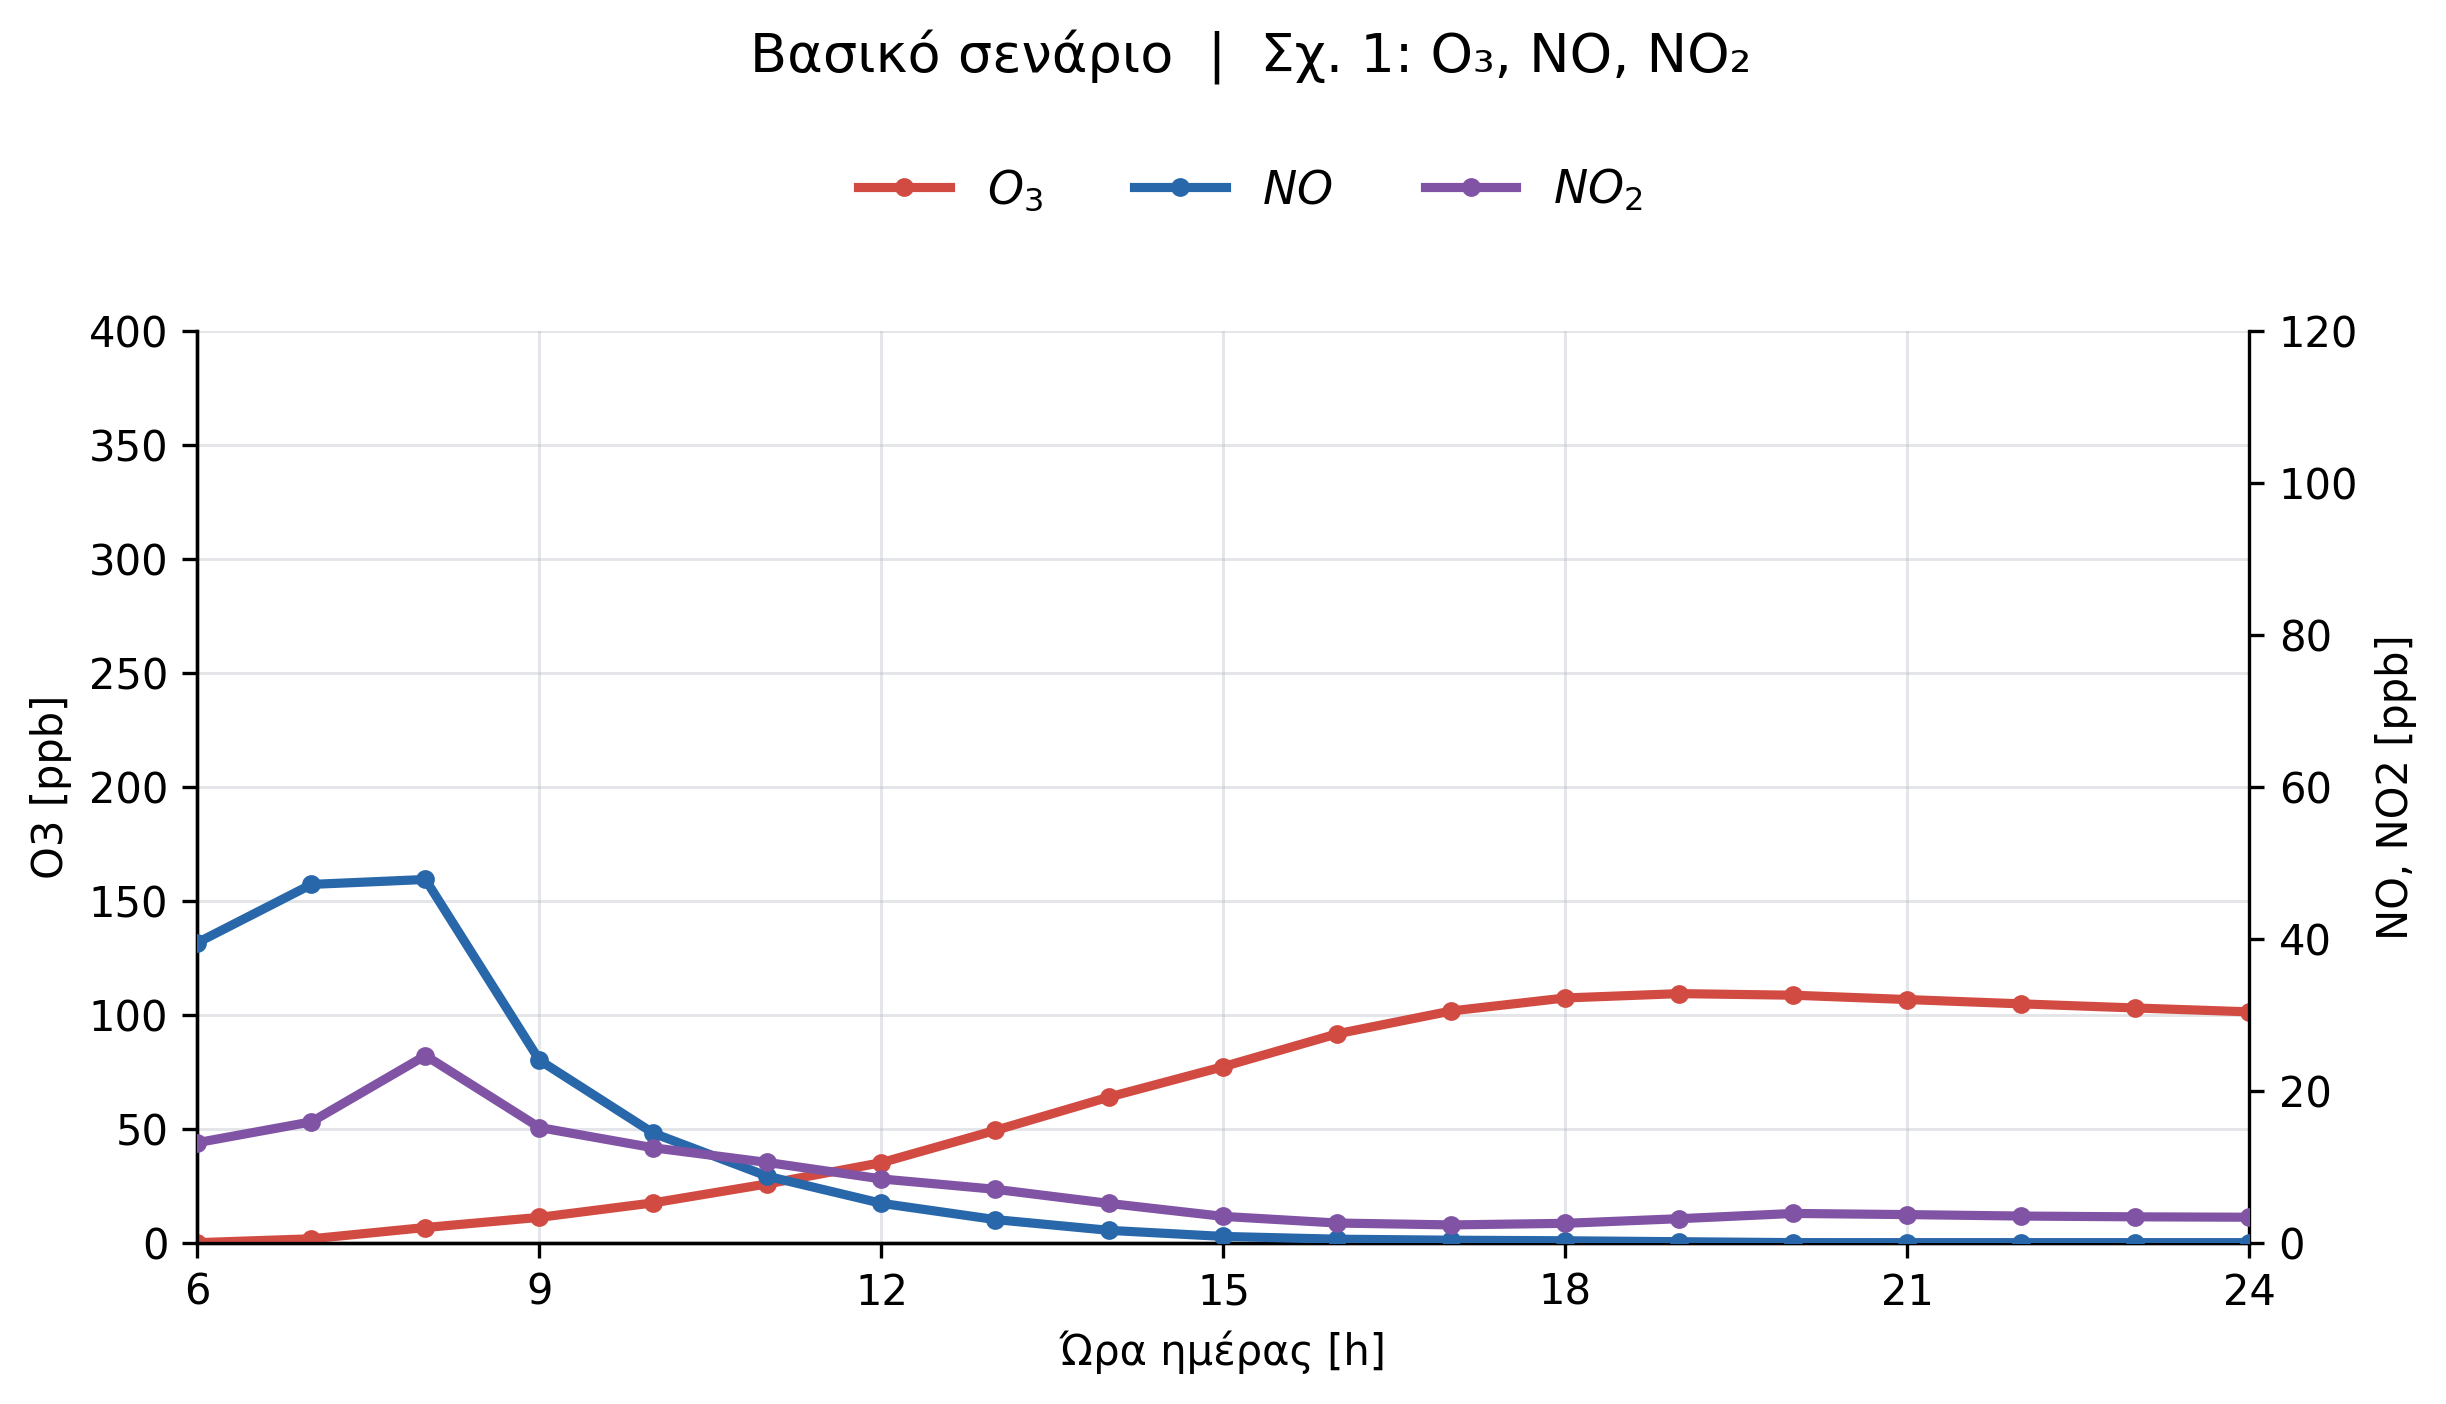

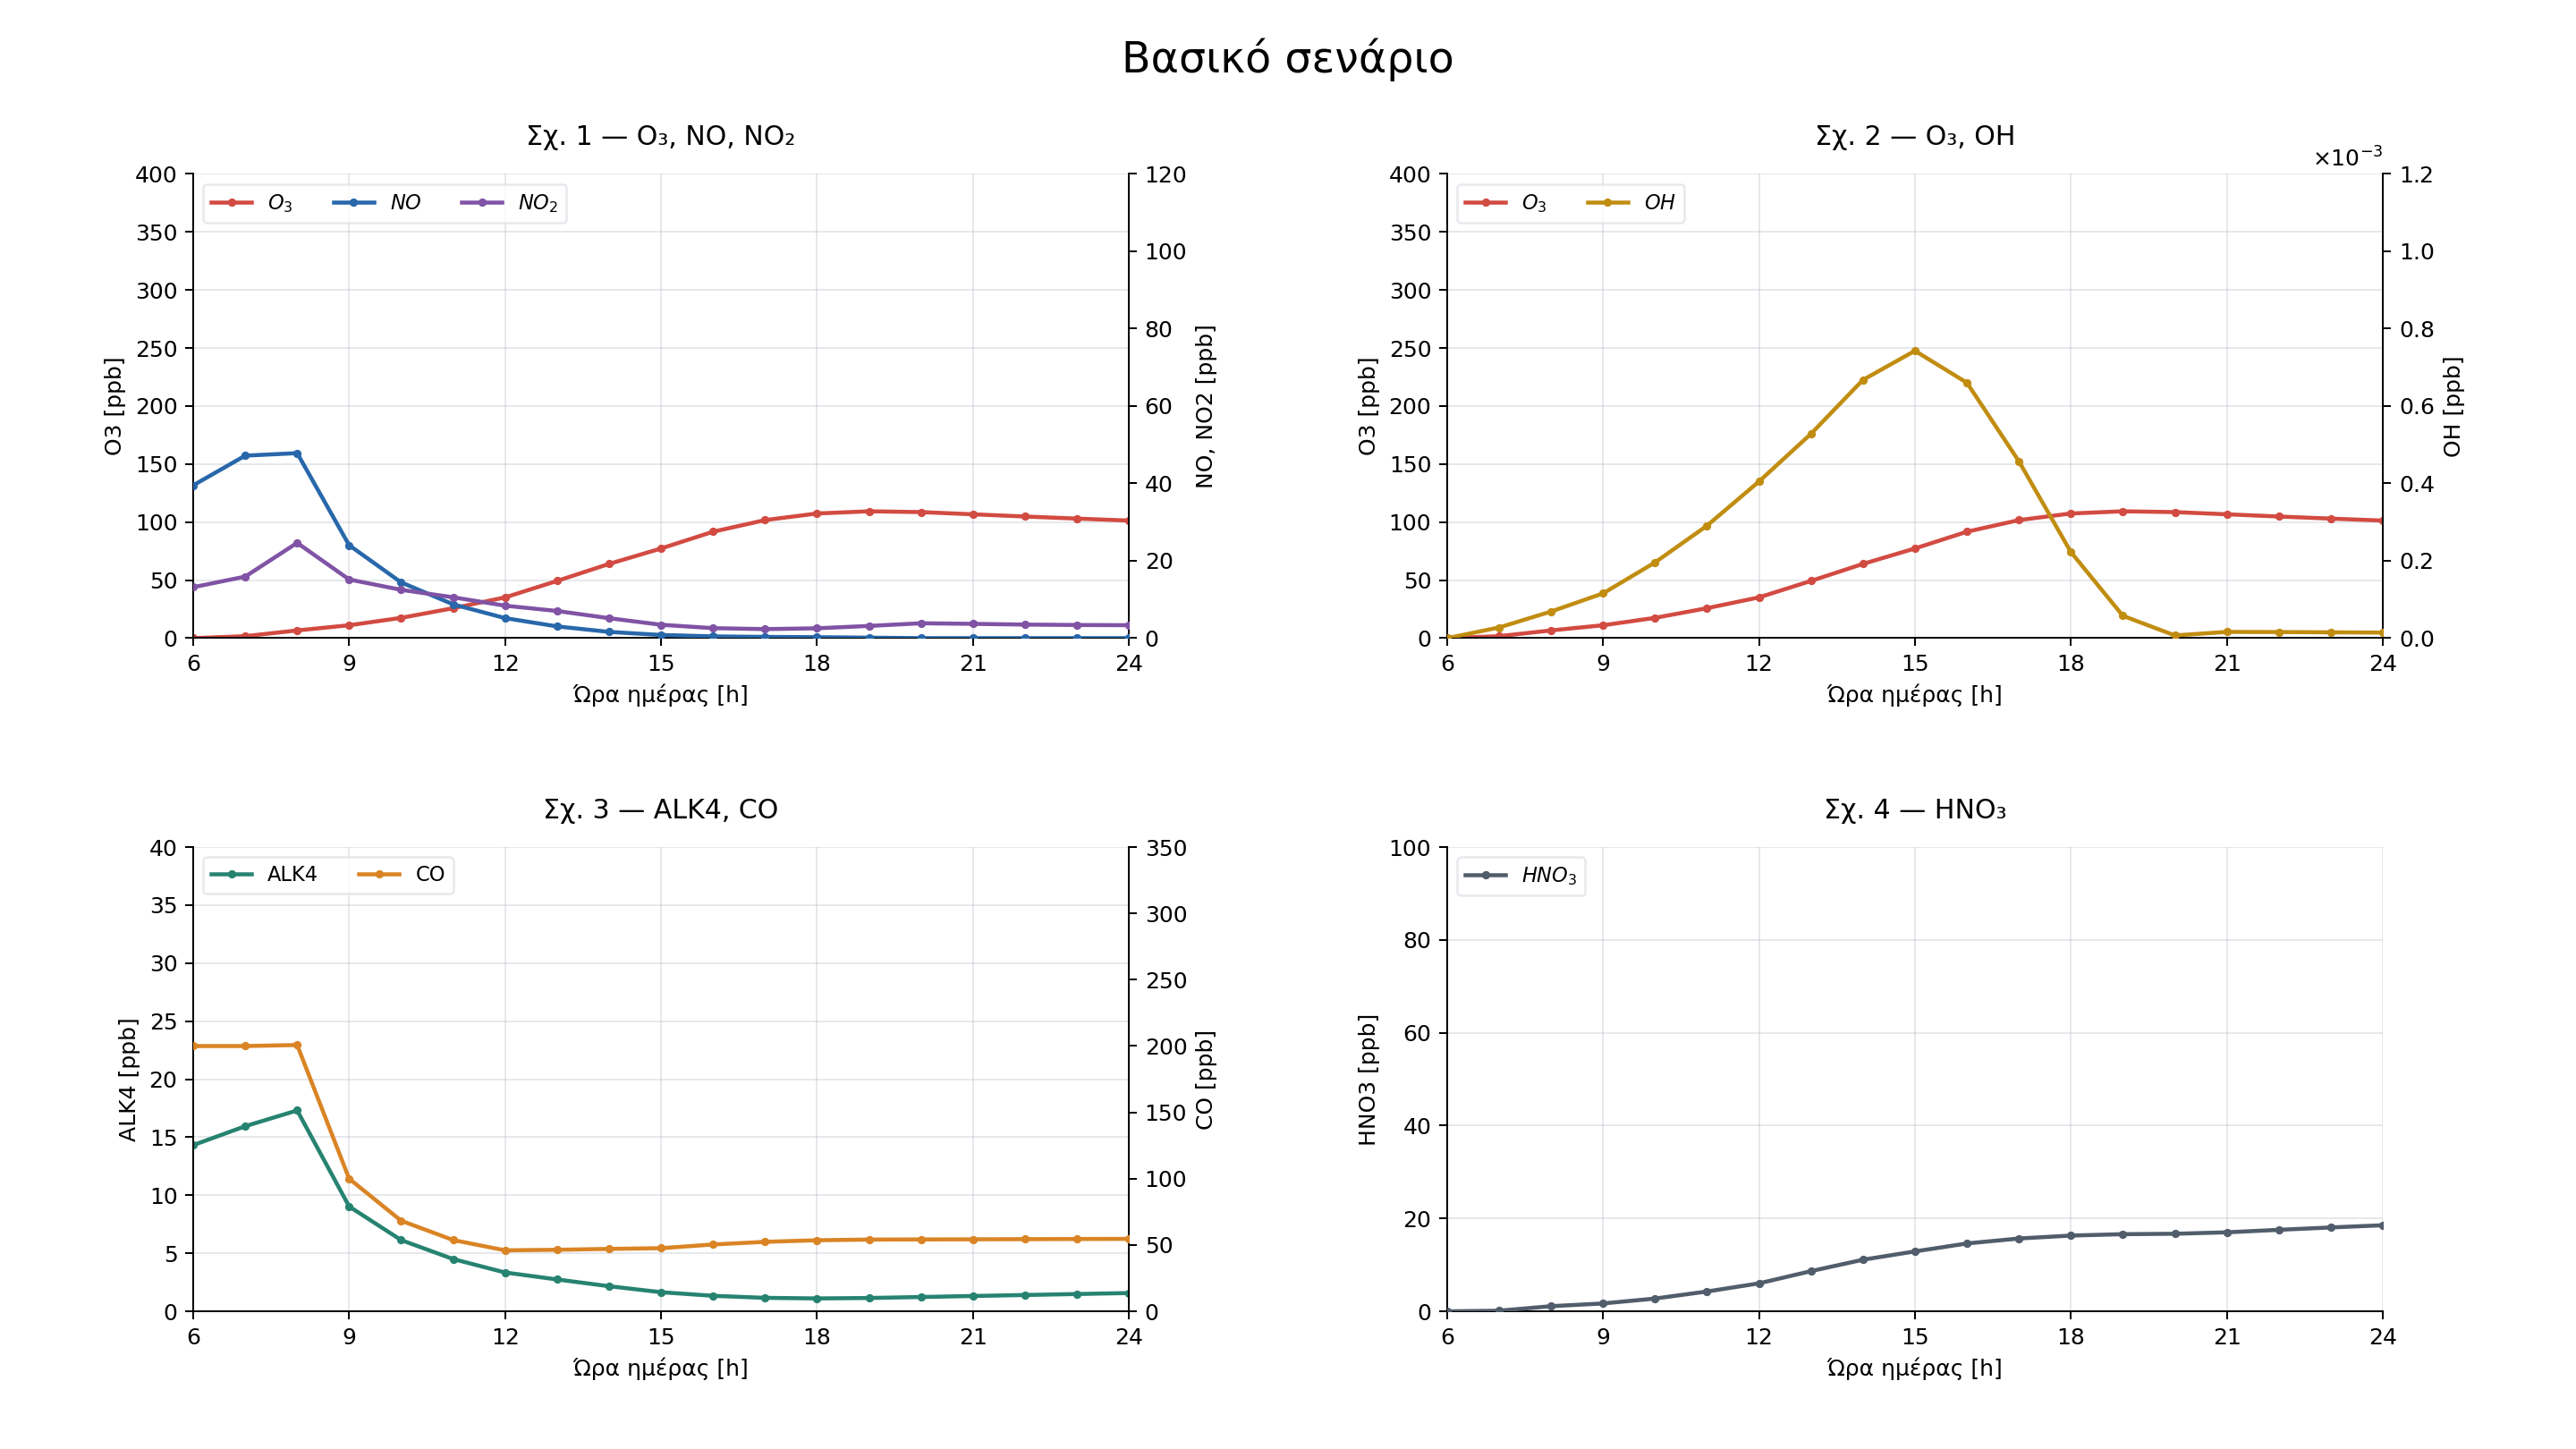

In [13]:
display(Image(filename=str(FIGURES_DIR/'baseline_Fig1.png'), width=820))
if MAKE_SLIDE_PANELS:
    display(Image(filename=str(SLIDES_DIR/'slide_baseline.png'), width=980))

---
### Πηγή δεδομένων και τρόπος εκτέλεσης

- **Μοναδική πηγή:** `Apotelesmata_ody(2).xlsx`, όπως ορίζεται από το `EXCEL_PATH`.
- Στο Google Colab ανεβάστε το Excel στο **Files → Upload** και εκτελέστε **Run all**. Στο τοπικό Jupyter τοποθετήστε το δίπλα στο notebook.
- Αν το Excel απουσιάζει, κάποιο από τα 12 φύλλα λείπει, ή τα δεδομένα δεν έχουν την αναμενόμενη μορφή, η εκτέλεση διακόπτεται με σφάλμα.
- Κάθε γραφική παράσταση και το PowerPoint εξάγονται από το λεξικό `data`, που προκύπτει αποκλειστικά από το Excel.
- Η πλήρης διαδρομή και το SHA-256 του χρησιμοποιημένου Excel τυπώνονται στο notebook για έλεγχο προέλευσης.
- Παραδοτέα: 18 βασικά PNG/PDF, 16 συμπληρωματικά PNG/PDF, 12 πάνελ 16:9, παρουσίαση PPTX, σύγκριση O₃, CSV ελέγχων και ZIP.
- Το `ppb` είναι υπόθεση για τις μονάδες συγκέντρωσης· χρειάζεται επιβεβαίωση από το αρχικό μοντέλο.
